# How the Abilities Work Together

*The Mathematics of Machine Intelligence · Chapter 34*

Follow the one update rule that recurs across the book, and test what a pair adds beyond its better member.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what options are on the list and whether the right answer could be missing, whether reports share a source, and which comparison is fair for the pair. Compute the effective size before multiplying evidence, compare a pair with its better member and with a relevant alternative, count costs, and say what a study did not test. The mathematics does not say whether a machine experiences anything.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 34, How the Abilities Work Together: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def multiply_and_rescale(weights, evidence):
    """x_i' = x_i g_i / sum_j x_j g_j. Returns None when the denominator is not positive."""
    weights = np.asarray(weights, dtype=float)
    evidence = np.asarray(evidence, dtype=float)
    if np.any(weights < 0) or np.any(evidence < 0):
        raise ValueError('Weights and evidence numbers must not be negative.')
    products = weights * evidence
    total = products.sum()
    if not total > 0:
        return None
    return products / total
LIKELIHOOD_SECOND = 0.2

def bayes_picture(prior_first=0.5, clue_first=0.8):
    prior = (prior_first, 1 - prior_first)
    evidence = (clue_first, LIKELIHOOD_SECOND)
    posterior = multiply_and_rescale(prior, evidence)
    products = (prior[0] * evidence[0], prior[1] * evidence[1])
    fig, ax = panels()
    xs = np.arange(2)
    ax[0].bar(xs - 0.18, prior, width=0.34, color=GREY, label='before the clue (prior)')
    if posterior is not None:
        ax[0].bar(xs + 0.18, posterior, width=0.34, color=TEAL, label='after the clue (posterior)')
        for x, v in zip(xs + 0.18, posterior):
            tag(ax[0], x, v + 0.02, sig(v), va='bottom', fontsize=9)
    else:
        tag(ax[0], 0.5, 0.5, 'posterior undefined:\nevery product is zero', color=TERRA)
    for x, v in zip(xs - 0.18, prior):
        tag(ax[0], x, v + 0.02, sig(v), va='bottom', fontsize=9, color=GREY)
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels(['first explanation', 'second explanation'], fontsize=9)
    ax[0].set(ylabel='weight', title='Multiply, then rescale to total one', ylim=(0, 1.2))
    ax[0].legend(fontsize=8, loc='upper center', ncol=1)
    grid = np.linspace(0, 1, 201)
    for prior_value, style, colour in [(0.2, 'dotted', GREY), (0.5, 'solid', TEAL)]:
        chosen = prior_value == prior_first
        ys = [multiply_and_rescale((prior_value, 1 - prior_value), (g, LIKELIHOOD_SECOND)) for g in grid]
        ax[1].plot(grid, [y[0] if y is not None else np.nan for y in ys], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'prior {prior_value:g}')
    if prior_first not in (0.2, 0.5):
        ys = [multiply_and_rescale(prior, (g, LIKELIHOOD_SECOND)) for g in grid]
        ax[1].plot(grid, [y[0] if y is not None else np.nan for y in ys], color=NAVY, linewidth=3, label=f'prior {prior_first:g}')
    if posterior is not None:
        ring(ax[1], clue_first, posterior[0])
    ax[1].set(xlabel='chance of the clue under the first explanation', ylabel='posterior weight on the first', title='Better-fitting explanations gain', ylim=(-0.02, 1.05))
    ax[1].legend(fontsize=8, loc='lower right')
    if posterior is None:
        metrics = {'Product, first explanation': sig(products[0]), 'Product, second explanation': sig(products[1]), 'Posterior, first': 'undefined (every product is zero)', 'Posterior odds, first to second': 'undefined (every product is zero)'}
        summary = 'Every explanation has weight zero or evidence zero, so the products total zero and rescaling would divide by zero. The update is undefined here, and the list needs an option with positive weight that fits the clue.'
        calc = f'Products: {prior[0]:g} x {clue_first:g} = {sig(products[0])} and {prior[1]:g} x {LIKELIHOOD_SECOND:g} = {sig(products[1])}. The total is 0.'
    else:
        odds = 'undefined (second posterior is zero)' if posterior[1] == 0 else sig(posterior[0] / posterior[1])
        metrics = {'Product, first explanation': sig(products[0]), 'Product, second explanation': sig(products[1]), 'Posterior, first': sig(posterior[0]), 'Posterior odds, first to second': odds}
        zero_note = ' A weight of zero stays zero, whatever the clue.' if prior_first in (0.0, 1.0) else ''
        summary = f'Starting at {sig(prior[0])} and {sig(prior[1])}, the products are {sig(products[0])} and {sig(products[1])}, which total {sig(sum(products))}. After rescaling the weights are {sig(posterior[0])} and {sig(posterior[1])}.{zero_note}'
        calc = f'Products: {prior[0]:g} x {clue_first:g} = {sig(products[0])} and {prior[1]:g} x {LIKELIHOOD_SECOND:g} = {sig(products[1])}. Total {sig(sum(products))}. Divide each by the total: {sig(posterior[0])} and {sig(posterior[1])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TYPES = ['round', 'wrinkled', 'speckled', 'striped']
OFFSPRING = np.array([1.0, 2.0, 4.0, 10.0])

def seed_shares(striped_share, generations):
    """Shares after repeated multiply-and-rescale. The chapter's field has no striped seeds (share 0)."""
    shares = np.array([0.5 - striped_share, 0.25, 0.25, striped_share])
    history = [shares]
    for _ in range(generations):
        shares = multiply_and_rescale(shares, OFFSPRING)
        history.append(shares)
    return history

def loss_weights(losses, eta=1.0):
    """The machine reading: the evidence number falls as an option's loss rises, g = exp(-eta x loss)."""
    return np.exp(-eta * np.asarray(losses, dtype=float))

def seeds_picture(striped_share=0.0, generations=1):
    history = seed_shares(striped_share, generations)
    start, now = (history[0], history[-1])
    fig, ax = panels()
    xs = np.arange(4)
    ax[0].bar(xs - 0.18, start, width=0.34, color=GREY, label='start of the field')
    ax[0].bar(xs + 0.18, now, width=0.34, color=TEAL, label=f'after {generations} update' + ('s' if generations != 1 else ''))
    for x, v in zip(xs + 0.18, now):
        tag(ax[0], x, v + 0.02, sig(v), va='bottom', fontsize=9)
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels(TYPES, fontsize=9)
    ax[0].set(ylabel='share of the field', title='Illustration, not data', ylim=(0, 1.15))
    ax[0].legend(fontsize=8, loc='upper left')
    full = seed_shares(striped_share, 8)
    colours = [GREY, GOLD, TEAL, TERRA]
    for k, name in enumerate(TYPES):
        ax[1].plot(range(9), [h[k] for h in full], color=colours[k], linewidth=2.2, marker='o', markersize=3.5, label=name)
    for k in range(4):
        ax[1].plot([generations], [now[k]], marker='o', markersize=10, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2)
    ax[1].set(xlabel='updates', ylabel='share of the field', title='Shares across repeated updates', ylim=(-0.02, 1.05))
    ax[1].legend(fontsize=8, loc='center right')
    products = start * OFFSPRING
    metrics = {'Round share': sig(now[0]), 'Wrinkled share': sig(now[1]), 'Speckled share': sig(now[2]), 'Striped share': sig(now[3])}
    first = seed_shares(striped_share, 1)[1]
    summary = f"Each update multiplies a type's share by its offspring (1, 2, 4, 10) and divides by the total {sig(products.sum())}. After {generations} update{('s' if generations != 1 else '')} the speckled share is {sig(now[2])} and the striped share is {sig(now[3])}" + (', still zero because a zero share stays zero.' if striped_share == 0 else ', growing from a small start.')
    losses = -np.log(OFFSPRING / OFFSPRING.max())
    same = multiply_and_rescale(start, loss_weights(losses))
    calc = f"Start {', '.join((sig(v) for v in start))}. Products {', '.join((sig(v) for v in products))}, total {sig(products.sum())}, first update {', '.join((sig(v) for v in first))}. The machine reading with losses {', '.join((sig(v) for v in losses))} and weight exp(-loss) gives {', '.join((sig(v) for v in same))} on the first update."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def effective_size(count, correlation):
    """n / (1 + (n - 1) rho) for equally noisy reports with one shared pairwise error correlation."""
    if count < 1:
        raise ValueError('Need at least one report.')
    denominator = 1 + (count - 1) * correlation
    if not denominator > 0:
        raise ValueError('The correlation is below the smallest value allowed for this count.')
    return count / denominator

def ceiling(correlation):
    return None if correlation <= 0 else 1 / correlation

def effective_picture(reports=8, correlation=0.3):
    n_eff = effective_size(reports, correlation)
    cap = ceiling(correlation)
    overcount = reports / n_eff
    fig, ax = panels()
    grid = np.unique(np.round(np.geomspace(1, 800, 160)).astype(int))
    for rho, style, colour in [(0.0, 'dotted', GREY), (0.021, 'dashed', GOLD), (0.1, 'dashdot', DARK_GOLD), (0.3, 'solid', TEAL)]:
        chosen = rho == correlation
        ax[0].plot(grid, [effective_size(int(g), rho) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label='independent' if rho == 0 else f'correlation {rho:g}')
    ring(ax[0], reports, n_eff)
    ax[0].set_xscale('log')
    ax[0].set_yscale('log')
    ax[0].set(xlabel='number of reports', ylabel='worth, in independent reports', title='Shared error caps what more reports add', ylim=(0.9, 1000))
    ax[0].legend(fontsize=8, loc='upper left')
    bars = ax[1].bar(['reports\ncounted', 'worth as\nindependent'], [reports, n_eff], color=[GREY, TEAL], width=0.5)
    for bar, v in zip(bars, [reports, n_eff]):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, v * 1.15, sig(v), va='bottom')
    ax[1].set_yscale('log')
    ax[1].set(ylabel='reports (log scale)', title='The headcount overstates the evidence', ylim=(0.8, max(reports * 4, 5)))
    cap_text = sig(cap) if cap is not None else 'none (independent reports keep adding)'
    metrics = {'Reports counted': reports, 'Worth in independent reports': sig(n_eff), 'Ceiling as reports are added': cap_text, 'Overcount if treated as independent (times)': sig(overcount)}
    summary = f'{reports} reports whose errors correlate at {sig(correlation)} are worth {sig(n_eff)} independent ones, so treating them as independent counts the evidence {sig(overcount)} times over. ' + (f'As reports are added the worth approaches {sig(cap)}.' if cap is not None else 'With no error correlation, each added report adds a full report.')
    calc = f'n_eff = n / (1 + (n - 1) rho) = {reports} / (1 + {reports - 1} x {sig(correlation)}) = {reports} / {sig(1 + (reports - 1) * correlation)} = {sig(n_eff)}. ' + (f'Ceiling 1/rho = {sig(cap)}.' if cap is not None else 'With rho = 0 there is no ceiling.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})
AI_SCORE = 80.0

def synergy(pair, human, machine):
    """The pair's score minus the better of the two working alone."""
    return pair - max(human, machine)

def synergy_picture(pair_score=75, human_score=70):
    s = synergy(pair_score, human_score, AI_SCORE)
    best_alone = max(human_score, AI_SCORE)
    better = 'the AI' if AI_SCORE > human_score else 'the person'
    fig, ax = panels()
    bars = ax[0].bar(['person\nalone', 'AI\nalone', 'pair'], [human_score, AI_SCORE, pair_score], color=[GOLD, GREY, TEAL], width=0.55)
    for bar, v in zip(bars, [human_score, AI_SCORE, pair_score]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, f'{v:g}', va='bottom')
    ax[0].axhline(best_alone, color=TERRA, linestyle='dashed', linewidth=1.5)
    ax[0].text(-0.45, best_alone + 1.2, f'better solo: {best_alone:g}', ha='left', va='bottom', fontsize=9, color=TERRA)
    ax[0].set(ylabel='answers right out of 100', title='The pair against its better member', ylim=(40, 108))
    grid = np.linspace(55, 95, 81)
    for person, style, colour in [(70, 'solid', TEAL), (90, 'dashed', GOLD)]:
        chosen = person == human_score
        ax[1].plot(grid, [synergy(g, person, AI_SCORE) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, label=f'person alone scores {person}')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ring(ax[1], pair_score, s)
    ax[1].set(xlabel="pair's score", ylabel='synergy (points)', title='Synergy is zero at the better solo score', xlim=(55, 95))
    ax[1].legend(fontsize=8, loc='upper left')
    verdict = 'the pair added something' if s > 0 else 'no gain over the better solo' if s == 0 else 'the better member alone did better'
    metrics = {'Better solo score': f'{best_alone:g} ({better})', "Pair's score": f'{pair_score:g}', 'Synergy (points)': sig(s), 'Reading': verdict}
    summary = f'With the person at {human_score:g}, the AI at {AI_SCORE:g} and the pair at {pair_score:g}, the better solo score is {best_alone:g} and synergy is {sig(s)} points. The pair is compared with the better member, so beating the weaker one is not enough.'
    calc = f'synergy = P_pair - max(P_H, P_A) = {pair_score:g} - max({human_score:g}, {AI_SCORE:g}) = {pair_score:g} - {best_alone:g} = {sig(s)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTED = {'all experiments': -0.23, 'person better alone': 0.46, 'AI better alone': -0.54}

def mixture_average(share_person_better):
    """Share-weighted mean of the two reported subgroup effects. The companion's arithmetic, not the review's pooling."""
    if not 0 <= share_person_better <= 1:
        raise ValueError('A share must lie between 0 and 1.')
    return share_person_better * REPORTED['person better alone'] + (1 - share_person_better) * REPORTED['AI better alone']

def share_reproducing_average(target=REPORTED['all experiments']):
    low, high = (REPORTED['AI better alone'], REPORTED['person better alone'])
    return (target - low) / (high - low)

def split_picture(share_person_better=0.31):
    mix = mixture_average(share_person_better)
    fig, ax = panels()
    names = ['all 106\nexperiments', 'person better\nalone', 'AI better\nalone']
    values = [REPORTED['all experiments'], REPORTED['person better alone'], REPORTED['AI better alone']]
    bars = ax[0].bar(names, values, color=[NAVY, TEAL, TERRA], width=0.55)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + (0.04 if v > 0 else -0.04), f'{v:+.2f}'.replace('+', ''), va='bottom' if v > 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set(ylabel='synergy, standardized difference', title='Reported by Vaccaro and colleagues', ylim=(-0.75, 0.68))
    ax[0].tick_params(axis='x', labelsize=8.5)
    grid = np.linspace(0, 1, 101)
    ax[1].plot(grid, [mixture_average(g) for g in grid], color=TEAL, linewidth=2.5, label='share-weighted mean of the two subgroup effects')
    ax[1].axhline(REPORTED['all experiments'], color=GREY, linestyle='dashed', linewidth=1.3, label='reported average, -0.23')
    ax[1].axhline(0, color=GREY, linewidth=0.8)
    ring(ax[1], share_person_better, mix)
    ax[1].set(xlabel='share of experiments where the person was better alone', ylabel='mean synergy', title='An average can hide a split', ylim=(-0.62, 0.55))
    ax[1].legend(fontsize=8, loc='lower right')
    target = share_reproducing_average()
    metrics = {'Mean at this share': sig(mix), 'Reported average': '-0.23', 'Share that would reproduce it': sig(target), 'Mean minus reported': sig(mix - REPORTED['all experiments'])}
    summary = f'If a share {sig(share_person_better)} of experiments had the person better alone (effect 0.46) and the rest the AI better alone (effect -0.54), a simple mean would be {sig(mix)}. A share of {sig(target)} would reproduce the reported -0.23, but the review pools effect sizes by meta-analysis, not by simple means.'
    calc = f'mean = share x 0.46 + (1 - share) x (-0.54) = {sig(share_person_better)} x 0.46 + {sig(1 - share_person_better)} x (-0.54) = {sig(mix)}. Solving mean = -0.23 gives share = (-0.23 + 0.54) / (0.46 + 0.54) = {sig(target)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
Z_ALPHA = 1.6448536
Z_POWER = 0.8416212
BETTER_SOLO = 0.8
GAIN = 0.05

def normal_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def paired_gain_variance(p_solo, p_pair, correlation):
    """Variance of one question's (pair correct minus solo correct), for correctness correlated across the two."""
    var_solo, var_pair = (p_solo * (1 - p_solo), p_pair * (1 - p_pair))
    both = p_solo * p_pair + correlation * math.sqrt(var_solo * var_pair)
    if both > min(p_solo, p_pair) + 1e-12 or both < max(0.0, p_solo + p_pair - 1) - 1e-12:
        raise ValueError('That correlation is not possible for these accuracies.')
    return var_solo + var_pair - 2 * correlation * math.sqrt(var_solo * var_pair)

def test_power(questions, correlation, p_solo=BETTER_SOLO, gain=GAIN):
    """Chance that a one-sided 5 percent test detects the gain, by the normal approximation."""
    var = paired_gain_variance(p_solo, p_solo + gain, correlation)
    se = math.sqrt(var / questions)
    return (1 - normal_cdf((Z_ALPHA * se - gain) / se), se)

def questions_for_power(correlation, p_solo=BETTER_SOLO, gain=GAIN):
    var = paired_gain_variance(p_solo, p_solo + gain, correlation)
    return var * ((Z_ALPHA + Z_POWER) / gain) ** 2

def power_picture(questions=200, correlation=0.5):
    power, se = test_power(questions, correlation)
    needed = questions_for_power(correlation)
    crit = Z_ALPHA * se
    fig, ax = panels()
    x = np.linspace(-0.1, 0.2, 500)
    density = lambda mean: np.exp(-0.5 * ((x - mean) / se) ** 2) / (se * math.sqrt(2 * math.pi))
    ax[0].plot(x * 100, density(0), color=GREY, linewidth=2, label='no real gain')
    ax[0].plot(x * 100, density(GAIN), color=TEAL, linewidth=2, label='a real 5 point gain')
    ax[0].fill_between(x * 100, 0, density(GAIN), where=x >= crit, color=TEAL, alpha=0.3, label='gain detected')
    ax[0].axvline(crit * 100, color=TERRA, linestyle='dashed', linewidth=1.5)
    top = ax[0].get_ylim()[1]
    ax[0].set_ylim(0, top * 1.28)
    tag(ax[0], crit * 100, top * 1.2, f'needs {sig(crit * 100)} points', color=TERRA, ha='left' if crit < 0.1 else 'right', fontsize=9)
    ax[0].set(xlabel='observed gain over the better solo score (points)', ylabel='relative likelihood', title=f'{questions} questions: power {sig(power)}')
    ax[0].legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.0, 0.85))
    grid = np.unique(np.round(np.geomspace(50, 3200, 80)).astype(int))
    for rho, style, colour in [(0.0, 'dotted', GREY), (0.5, 'solid', TEAL), (0.8, 'dashed', GOLD)]:
        chosen = rho == correlation
        ax[1].plot(grid, [test_power(int(g), rho)[0] for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'answers correlated {rho:g}')
    ax[1].axhline(0.8, color=GREY, linestyle='dashed', linewidth=1)
    ring(ax[1], questions, power)
    ax[1].set_xscale('log')
    ax[1].set_xticks([100, 200, 400, 800, 1600])
    ax[1].set_xticklabels(['100', '200', '400', '800', '1600'])
    ax[1].minorticks_off()
    ax[1].set(xlabel='questions', ylabel='chance of detecting the gain', title='Power rises with questions', ylim=(0, 1.03))
    ax[1].legend(fontsize=8, loc='lower right')
    metrics = {'Chance of detecting a 5 point gain': sig(power), 'Gain needed to count (points)': sig(crit * 100), 'Questions for 80 percent power': sig(math.ceil(needed)), 'Standard error of the gain (points)': sig(se * 100)}
    summary = f"With {questions} questions and the pair's and the better solo's answers correlated at {sig(correlation)}, a real 5 point gain is detected {sig(100 * power)} percent of the time. About {math.ceil(needed)} questions would give 80 percent. These are illustrative constructed assumptions, not a result."
    calc = f'Per-question variance of the difference = 0.8 x 0.2 + 0.85 x 0.15 - 2 x {sig(correlation)} x sqrt(0.16 x 0.1275) = {sig(paired_gain_variance(BETTER_SOLO, BETTER_SOLO + GAIN, correlation))}. se = sqrt(var/{questions}) = {sig(se)}; power = 1 - Phi((1.645 se - 0.05)/se) = {sig(power)}; questions for 80 percent = var x ((1.645 + 0.842)/0.05)^2 = {sig(needed)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C34-D01: How does one clue reweight two explanations?

Two explanations start with weights. A clue fits one better. What happens when each weight is multiplied by its fit and the weights are rescaled to total one?

Each explanation's weight is multiplied by how probable the clue would be under it. The products no longer total one, so each is divided by their total. The result is the posterior. The odds change by exactly the ratio of the two likelihoods, so a clue four times as likely under the first explanation moves even odds to four to one.

$$
x_i'=\frac{x_i\,g_i}{\sum_j x_j\,g_j}
$$

**Symbols:** x_i: option i's weight now (the prior), not below zero; g_i: its evidence number: how well it fits the clue (the likelihood), not below zero; x_i': its weight after the update (the posterior); sum_j x_j g_j: the total of the products, which rescales the weights; it must be positive

**Predict before looking:** With both explanations starting at 0.5 and the clue 4 times as likely under the first, predict the new weights before looking.

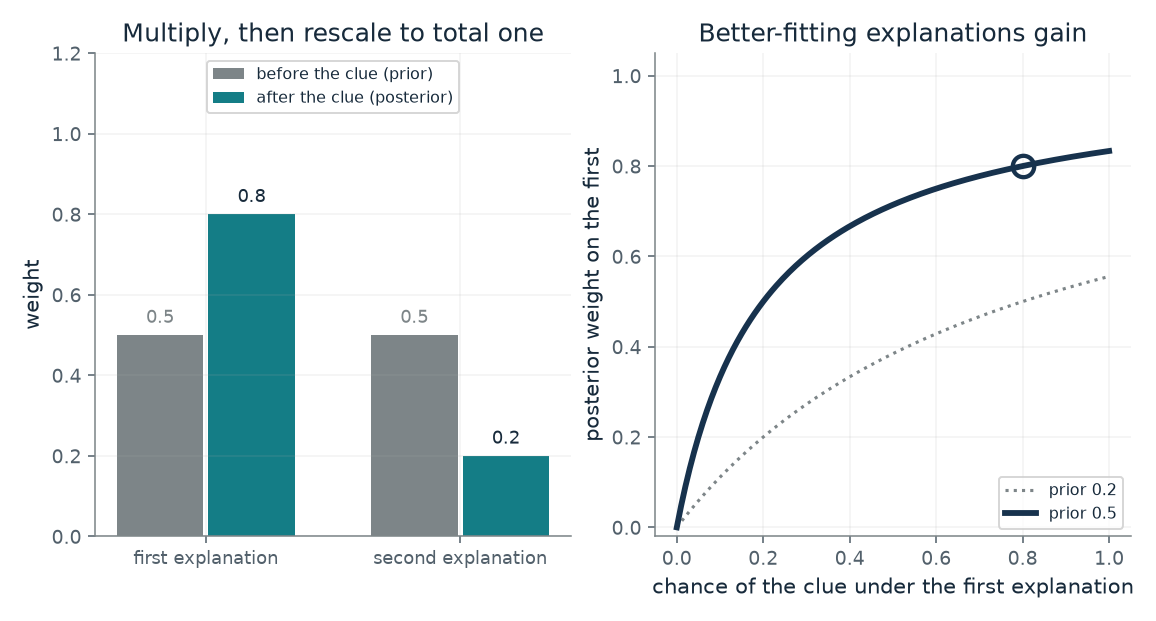

- **Product, first explanation:** 0.4
- **Product, second explanation:** 0.1
- **Posterior, first:** 0.8
- **Posterior odds, first to second:** 4

Starting at 0.5 and 0.5, the products are 0.4 and 0.1, which total 0.5. After rescaling the weights are 0.8 and 0.2.

Products: 0.5 x 0.8 = 0.4 and 0.5 x 0.2 = 0.1. Total 0.5. Divide each by the total: 0.8 and 0.2.

In [2]:
figure, values, explanation = bayes_picture(**{'prior_first': 0.5, 'clue_first': 0.8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does one clue reweight two explanations?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Starting weight on the first explanation = 0.5, Chance of the clue under the first explanation = 0.8: The products are 0.4 and 0.1, totaling 0.5, so the weights become 0.8 and 0.2, odds of 4 to 1, the clue's likelihood ratio. Set the prior to 0 and the first stays at 0 whatever the clue says.

**Takeaway:** Multiplying by the fit and rescaling moves weight toward the better-fitting option, and a weight of zero cannot be revived by any evidence.

**Why it matters:** The same step recurs through the book. Its guarantees are exact: a zero weight stays zero, and a common positive factor cancels. Its weakness is also exact: wrong likelihoods or an omitted option give a confident wrong answer.

**In brains and behavior:** In Ernst and Banks's study four people judged bar height close to a reliability-weighted average of sight and touch. The match to multiply-and-rescale is the book's derivation, not the study's test, and the study recorded nothing from the brain.

**In machines:** Arora, Hazan and Kale surveyed a rule of this shape as multiplicative weights, repeatedly discovered in several fields. The survey says nothing about beliefs or attention, and nothing here describes any particular decoder.

**Where it applies:** The options listed are the only options, the evidence numbers are right, and the same evidence is not counted twice. An option left off the list cannot be recovered by rescaling.

**Check your understanding:** The first explanation starts at 0.2 and the clue's chance is 0.5 under the first and 0.2 under the second. What are the new weights?

<details><summary>Show the answer</summary>

Products are 0.2 x 0.5 = 0.1 and 0.8 x 0.2 = 0.16, totaling 0.26. The weights become 0.1/0.26 = 0.385 and 0.615.

</details>

*Source: Chapter 34, Multiply the evidence, then rescale. Book formula, Bayes' rule for any number of options. The chapter's invented example is two explanations at 0.5 each and a clue of probability 0.8 under the first and 0.2 under the second. The other starting weights and clue chances are the companion's variations.*

## C34-D02: What does the same update do to a field of seeds?

Round, wrinkled, speckled and striped seeds leave 1, 2, 4 and 10 offspring per plant. What happens to their shares under repeated multiply-and-rescale?

Each update multiplies a type's share by its offspring and divides by the total, so speckled doubles from a quarter to a half while round halves. Repeating the update makes the most fertile present type take over. A striped share of exactly zero stays zero forever, but even a small positive start grows fastest.

$$
x_i'=\frac{x_i\,f_i}{\sum_j x_j\,f_j}
$$

**Symbols:** x_i: type i's share of the field; f_i: the offspring each plant of type i leaves (a fitness, not below zero); x_i': its share after one update

**Predict before looking:** Striped seeds would do best, but the field holds none. Predict the striped share after one update and after eight, and whether a small starting share changes that.

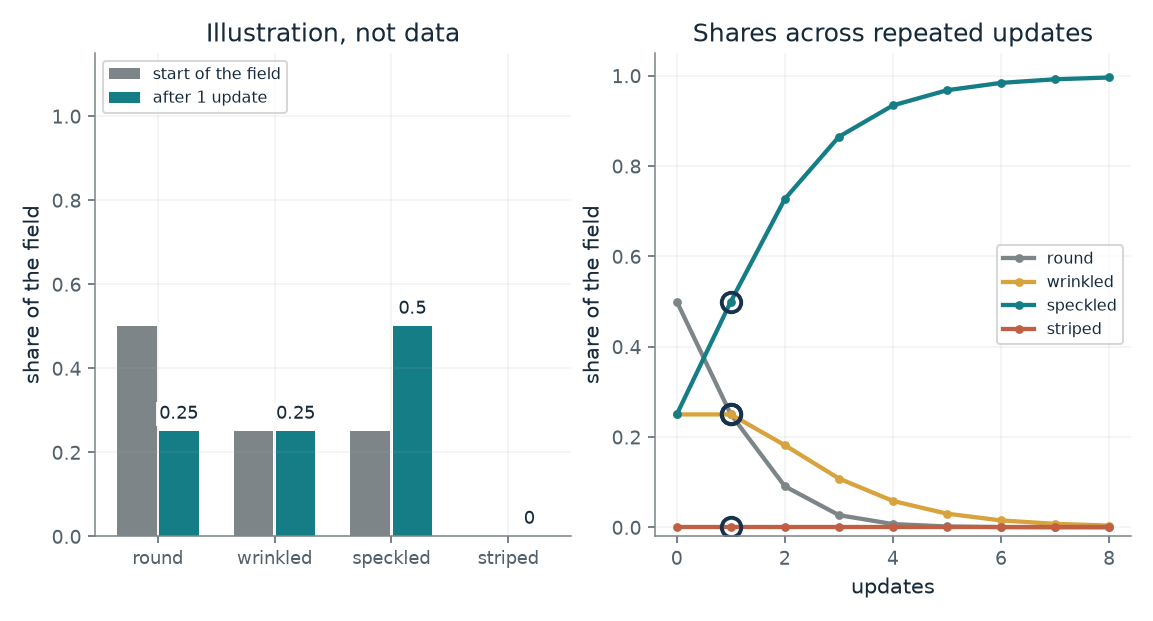

- **Round share:** 0.25
- **Wrinkled share:** 0.25
- **Speckled share:** 0.5
- **Striped share:** 0

Each update multiplies a type's share by its offspring (1, 2, 4, 10) and divides by the total 2. After 1 update the speckled share is 0.5 and the striped share is 0, still zero because a zero share stays zero.

Start 0.5, 0.25, 0.25, 0. Products 0.5, 0.5, 1, 0, total 2, first update 0.25, 0.25, 0.5, 0. The machine reading with losses 2.3, 1.61, 0.916, 0 and weight exp(-loss) gives 0.25, 0.25, 0.5, 0 on the first update.

In [3]:
figure, values, explanation = seeds_picture(**{'striped_share': 0.0, 'generations': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does the same update do to a field of seeds?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Striped share at the start = 0.0, Updates applied = 1: One update gives round 0.25, wrinkled 0.25, speckled 0.5 and striped 0, matching the chapter. Striped stays at zero however well it would have done. Switch the striped start to 0.05 and it passes every other type by the second update.

**Takeaway:** A type with no share cannot appear, however fit it would be. The best option not on the list is never found by this step.

**Why it matters:** This is the chapter's exact, carried-over fact: rescaling cannot add an answer the list omits. A person or a check on the list has to supply the missing option.

**In brains and behavior:** No brain is modeled here. The chapter says whether any brain computes this step is open, and a weight means a share of a population in one reading, a belief in another and a machine's trust in the third.

**In machines:** With losses 2.30, 1.61, 0.916 and 0 and a weight of exp(-loss), a machine's multiplicative weights give the same first-update shares as the ledger. That is a match of numbers chosen to match, not a claim about any system.

**Where it applies:** Fixed offspring numbers, no mutation or migration, and shares that are shares of a population. The chapter notes that the same arithmetic also reads as a likelihood in inference and as a loss-based weight in a machine, with the numbers chosen to match.

**Check your understanding:** In the chapter's field, what are the products and the total before rescaling?

<details><summary>Show the answer</summary>

Round 0.5 x 1 = 0.5, wrinkled 0.25 x 2 = 0.5, speckled 0.25 x 4 = 1.0 and striped 0 x 10 = 0, totaling 2, so the new shares are 0.25, 0.25, 0.5 and 0.

</details>

*Source: Chapter 34, Multiply the evidence, then rescale. The chapter's illustration with no real data: round 0.5 leaving 1, wrinkled 0.25 leaving 2, speckled 0.25 leaving 4, and striped, which would leave 10, absent from the field. One update gives 0.25, 0.25, 0.5 and 0. The small striped starts and repeated updates are the companion's extension, not in the chapter.*

## C34-D03: How many independent reports are eight related reports worth?

If reports share errors, how much does a headcount overstate the evidence, and what caps what more reports can add?

The variance of the average of n reports with pairwise correlation rho is the single-report variance times (1 + (n - 1) rho) / n. An independent panel of size n_eff has variance divided by n_eff, so equating the two gives the formula. As n grows the average variance approaches rho times the single variance, and the worth approaches 1/rho.

$$
n_{\text{eff}}=\frac{n}{1+(n-1)\rho},\qquad n_{\text{eff}}\to\frac{1}{\rho}\ \text{as}\ n\to\infty
$$

**Symbols:** n: the number of reports, each equally noisy; rho: the error correlation between any two reports, from 0 up to 1 here; n_eff: how many independent reports would give an average as steady

**Predict before looking:** Predict the effective size of 787 reports at the chosen correlation 0.021, before changing the controls.

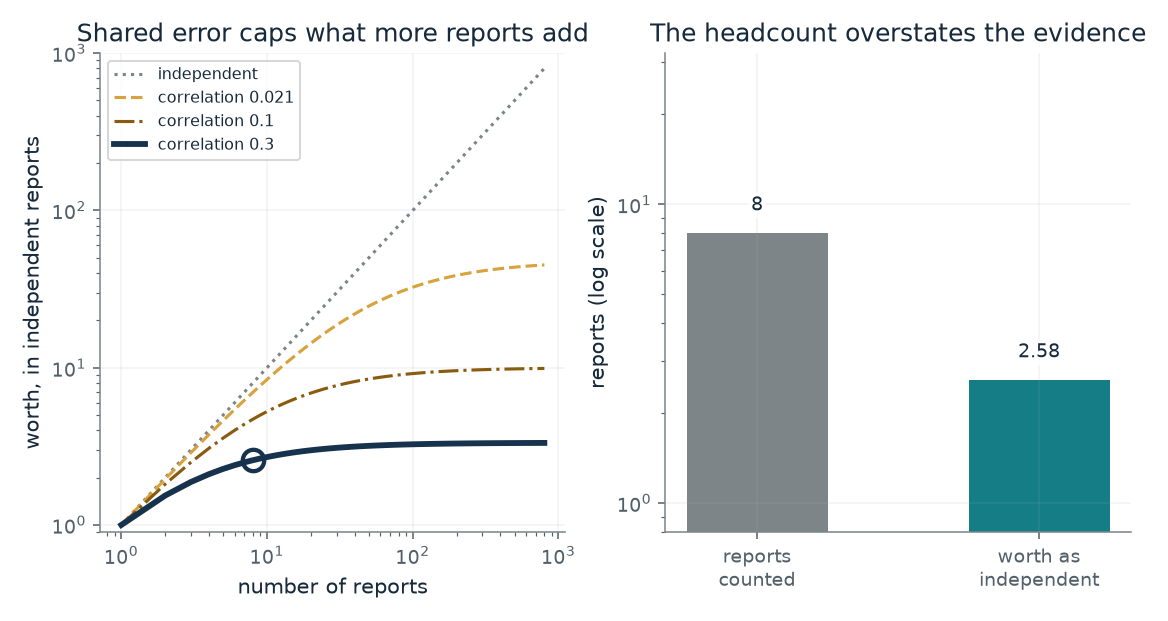

- **Reports counted:** 8
- **Worth in independent reports:** 2.58
- **Ceiling as reports are added:** 3.33
- **Overcount if treated as independent (times):** 3.1

8 reports whose errors correlate at 0.3 are worth 2.58 independent ones, so treating them as independent counts the evidence 3.1 times over. As reports are added the worth approaches 3.33.

n_eff = n / (1 + (n - 1) rho) = 8 / (1 + 7 x 0.3) = 8 / 3.1 = 2.58. Ceiling 1/rho = 3.33.

In [4]:
figure, values, explanation = effective_picture(**{'reports': 8, 'correlation': 0.3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many independent reports are eight related reports worth?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of reports = 8, Error correlation between any two reports = 0.3: Eight reports at correlation 0.3 are worth 8/3.1, about 2.6 independent reports, and no number of such reports can exceed 10/3, about 3.3. Multiplying their likelihoods as if independent would count the evidence about 3.1 times over.

**Takeaway:** Shared errors cap what more reports can add. A large headcount of related reports can be worth only a handful of independent ones.

**Why it matters:** Multiply-and-rescale cannot tell whether two reports repeat the same source. Computing the effective size first says how much evidence the reports really carry.

**In brains and behavior:** People who saw one another's answers, as Chapter 23 reported, can share errors. The chapter says Galton does not claim his guessers did.

**In machines:** Language models trained on overlapping material can fail together. Chapter 23 reported measured overlap in wrong answers, and a second model adds information only if it offers evidence the first lacks.

**Where it applies:** Equally noisy reports, one correlation shared by every pair, bell-shaped errors, and the same shift in every report. The formula describes variance, not shared bias: a very steady average can still be systematically wrong.

**Check your understanding:** Four reports have error correlation 0.2. What are they worth, and what is the most any number of such reports could be worth?

<details><summary>Show the answer</summary>

4 / (1 + 3 x 0.2) = 4/1.6 = 2.5 independent reports. The ceiling is 1/0.2 = 5.

</details>

*Source: Chapter 34, In an illustrative case, eight reports that share errors count as 2.6. Book formula. Eight reports at correlation 0.3 give 2.6 and a ceiling of 10/3, the chapter's illustrative case. The 787 guesses at correlation 0.021 are Chapter 23's invention: the 787-to-45 ledger is not a finding that Galton's guessers shared errors.*

## C34-D04: Did the pair add anything beyond its better member?

A person, an AI and the pair take the same task. How is the pair's score judged against the two working alone?

The max picks whichever member did better alone, and the pair is scored against that member. A pair that outscores the person but trails the AI has negative synergy. A faster answer or a lower cost can still matter, which is why the chapter says to count costs, but it does not make the pair a better scorer than its better member.

$$
\text{synergy}=P_{\text{pair}}-\max(P_H,P_A)
$$

**Symbols:** P_pair: the pair's score; P_H, P_A: the person's and the AI's scores alone, on the same task and scale; max: the larger of the two solo scores: the better-solo baseline

**Predict before looking:** With the person at 70 and the AI at 80, predict the pair's score at which synergy is zero, and whether a pair that beats the person is a pair that adds value.

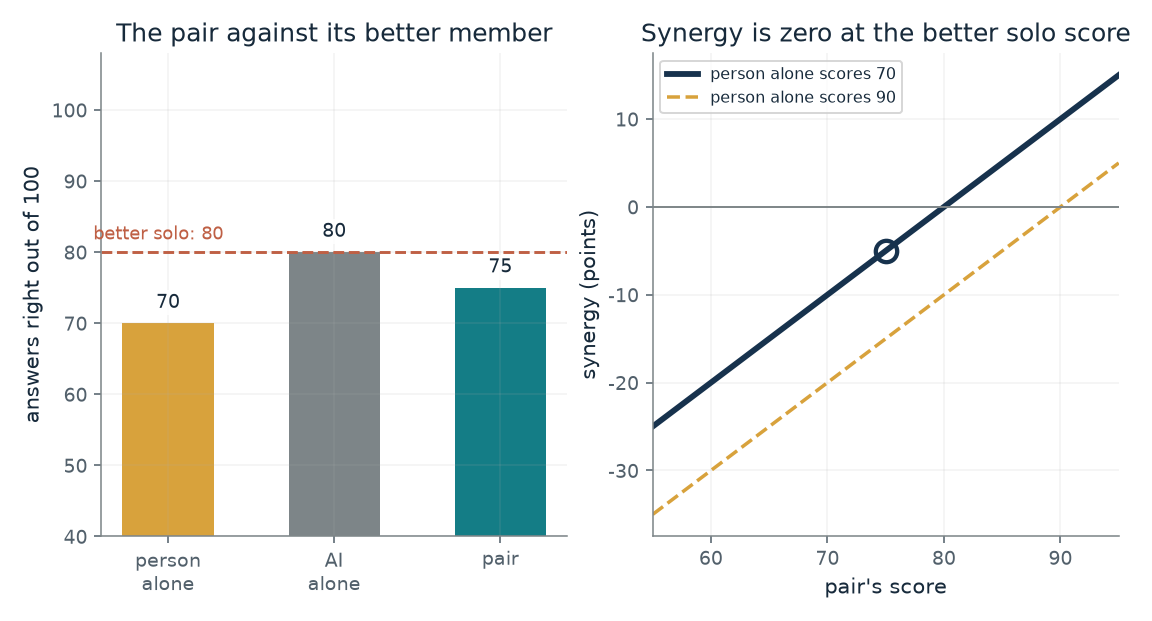

- **Better solo score:** 80 (the AI)
- **Pair's score:** 75
- **Synergy (points):** -5
- **Reading:** the better member alone did better

With the person at 70, the AI at 80 and the pair at 75, the better solo score is 80 and synergy is -5 points. The pair is compared with the better member, so beating the weaker one is not enough.

synergy = P_pair - max(P_H, P_A) = 75 - max(70, 80) = 75 - 80 = -5.

In [5]:
figure, values, explanation = synergy_picture(**{'pair_score': 75, 'human_score': 70})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Did the pair add anything beyond its better member?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Pair's score = 75, Person alone = 70: The pair at 75 beats the person's 70 by 5 and falls 5 short of the AI's 80, so synergy is minus 5. Raise the person's score to 90 and the baseline switches to the person.

**Takeaway:** Beating the weaker member is easy. A pair adds value only by passing the better one, and which member is better depends on the task.

**Why it matters:** A partnership claim needs the right comparison. Comparing the pair with the weaker partner, or with nothing, can make any pair look useful.

**In brains and behavior:** A person's solo score is what the person does without the machine. It depends on the task and the person, and these numbers are constructed.

**In machines:** An AI's solo score is the machine alone on the same task. Where a machine alone cannot do the task, the chapter says to compare against a relevant existing alternative instead.

**Where it applies:** All three scores come from the same task on the same scale, higher is better. The review excluded tasks that either side cannot do alone, so a case where only the pair can act lies outside this yardstick; there, test a relevant existing alternative instead.

**Check your understanding:** The person scores 90, the AI 80 and the pair 85. What is the synergy, and which member is the baseline?

<details><summary>Show the answer</summary>

The baseline is the person, 90, so synergy = 85 - 90 = minus 5.

</details>

*Source: Chapter 34, Across 106 experiments, pairs on average trailed the better of the two alone. Book formula, a simple version of the standardized difference used by Vaccaro, Almaatouq and Malone. The scores 70 (person), 80 (AI) and 75 (pair) are the chapter's constructed example, giving synergy of minus 5; the person's other score, 90, is the companion's variation. Chapter 1's version of this example is the same arithmetic.*

## C34-D05: How can an average of minus 0.23 hide gains and losses?

Across 106 experiments pairs trailed the better member by 0.23 on average, yet the pair gained when the person was better alone. How do those fit together?

A mean of two subgroup effects sits between them, closer to the larger subgroup. The reported overall effect is nearer the AI-better effect, which is what a mixture dominated by that kind of experiment would produce. The review's pooling is not this simple, so the share is illustrative.

$$
\bar d=q\,d_{H}+(1-q)\,d_{A},\qquad d_H=0.46,\ d_A=-0.54
$$

**Symbols:** d_H: the reported synergy when the person alone was better, 0.46; d_A: the reported synergy when the AI alone was better, minus 0.54; q: the share of experiments where the person was better alone (an assumption here; the chapter does not give it); d-bar: the share-weighted mean of the two subgroup effects

**Predict before looking:** Predict whether the reported overall average of minus 0.23 lies closer to the person-better effect or to the AI-better effect.

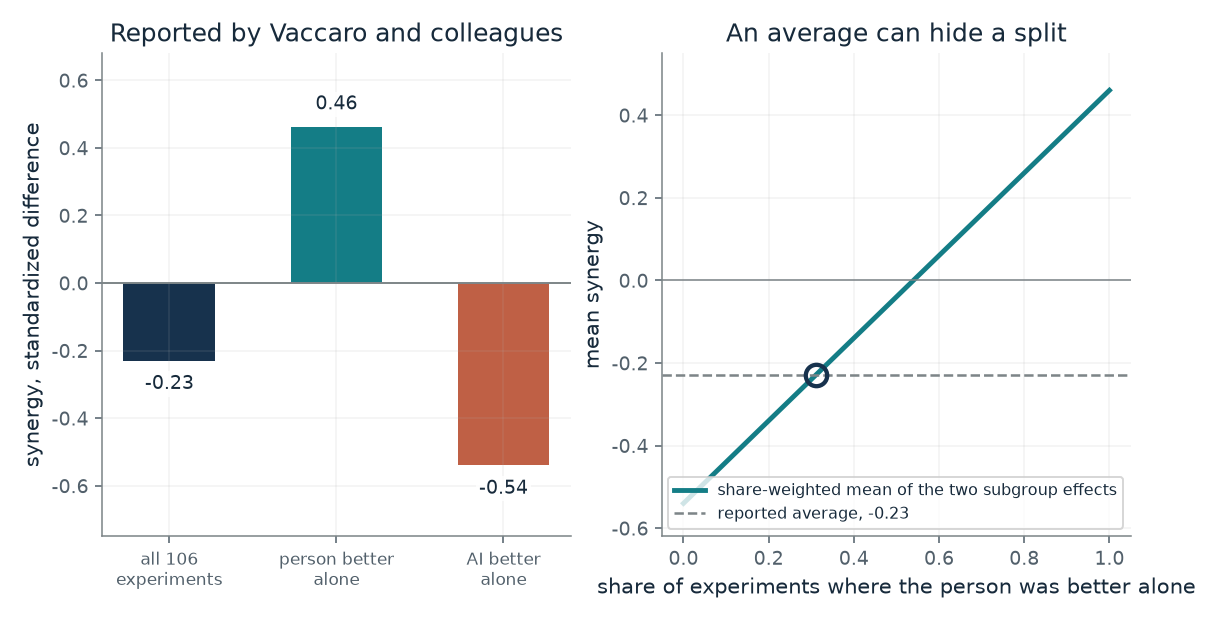

- **Mean at this share:** -0.23
- **Reported average:** -0.23
- **Share that would reproduce it:** 0.31
- **Mean minus reported:** 0

If a share 0.31 of experiments had the person better alone (effect 0.46) and the rest the AI better alone (effect -0.54), a simple mean would be -0.23. A share of 0.31 would reproduce the reported -0.23, but the review pools effect sizes by meta-analysis, not by simple means.

mean = share x 0.46 + (1 - share) x (-0.54) = 0.31 x 0.46 + 0.69 x (-0.54) = -0.23. Solving mean = -0.23 gives share = (-0.23 + 0.54) / (0.46 + 0.54) = 0.31.

In [6]:
figure, values, explanation = split_picture(**{'share_person_better': 0.31})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How can an average of minus 0.23 hide gains and losses?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of experiments where the person was better alone = 0.31: A share of about 0.31 gives 0.31 x 0.46 + 0.69 x (-0.54) = -0.23, matching the reported average. That is arithmetic, not a finding. The same overall number would also arise from many other splits if the effects differed.

**Takeaway:** An average near zero or below it can hide a large gain when the person is the stronger member and a large loss when the machine is.

**Why it matters:** A single average cannot say whether a pair helps. The authors do not think the result means combining people and AI is a bad idea, and the split shows why the answer depends on who is better alone.

**In brains and behavior:** The person-better case is where the pair gained over its better member. The review compared people, machines and pairs on the same tasks, and it measured no brain activity.

**In machines:** The AI-better case is where the pair lost to the machine alone. Whether a pair can be routed to the better member for each question is one of the features the chapter's proposed test would add.

**Where it applies:** The mixture treats the two subgroup effects as simple averages over all experiments. The review does not give a share of person-better experiments and does not pool this way, so the share that reproduces the reported average is only a way of seeing how an average of opposite effects can land near zero.

**Check your understanding:** If exactly half the experiments had the person better alone, what would the simple mean of the two subgroup effects be?

<details><summary>Show the answer</summary>

0.5 x 0.46 + 0.5 x (-0.54) = -0.04, much closer to zero than the reported -0.23.

</details>

*Source: Chapter 34, Across 106 experiments, pairs on average trailed the better of the two alone. The three numbers are those the chapter reports from Vaccaro, Almaatouq and Malone (2024): minus 0.23 overall, plus 0.46 when the person alone was better, minus 0.54 when the AI alone was better, on one standardized scale. The share-weighted mean is the companion's own arithmetic; the review's overall figure is a meta-analytic pooling of 370 effect sizes, not a simple mean.*

## C34-D06: How many questions could a proposed test need?

The chapter sketches a test on 200 yes-or-no questions with a target gain of five points, and says 200 may be too few. Under what assumptions is it too few?

The observed gain has a standard error that shrinks with the square root of the number of questions and with the correlation between the two sets of answers. The test counts a gain when it exceeds about 1.645 standard errors. The chance of passing that bar, when a real 5 point gain exists, is the power.

$$
\text{power}=1-\Phi\!\left(\frac{z_{\alpha}\,\mathrm{se}-\delta}{\mathrm{se}}\right),\qquad \mathrm{se}=\sqrt{\frac{V}{N}},\quad N_{80}=V\left(\frac{z_{\alpha}+z_{\beta}}{\delta}\right)^{2}
$$

**Symbols:** delta: the gain the test should detect: 0.05, the chapter's illustrative target; V: the variance of one question's pair-minus-solo result; it shrinks as the two sets of answers correlate; N: the number of questions; z_alpha, z_beta: 1.645 for a one-sided 5 percent test and 0.842 for 80 percent power; Phi: the standard normal cumulative distribution

**Predict before looking:** Predict whether 200 questions give at least an 80 percent chance of detecting a real 5 point gain when the pair's and the solo's answers are correlated at 0.5.

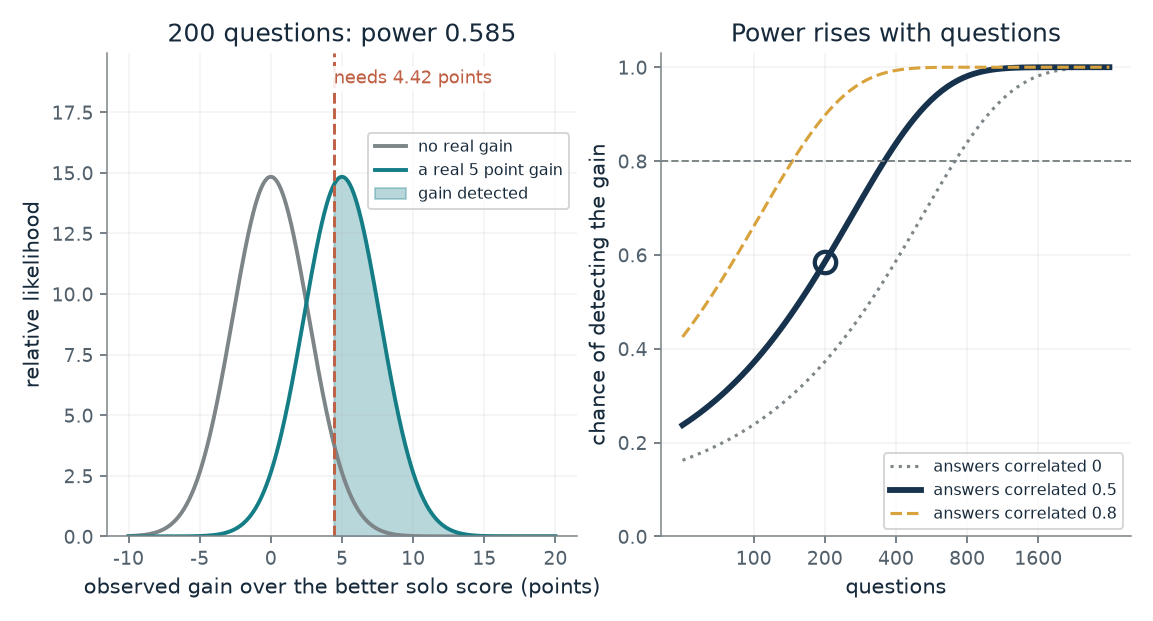

- **Chance of detecting a 5 point gain:** 0.585
- **Gain needed to count (points):** 4.42
- **Questions for 80 percent power:** 358
- **Standard error of the gain (points):** 2.69

With 200 questions and the pair's and the better solo's answers correlated at 0.5, a real 5 point gain is detected 58.5 percent of the time. About 358 questions would give 80 percent. These are illustrative constructed assumptions, not a result.

Per-question variance of the difference = 0.8 x 0.2 + 0.85 x 0.15 - 2 x 0.5 x sqrt(0.16 x 0.1275) = 0.145. se = sqrt(var/200) = 0.0269; power = 1 - Phi((1.645 se - 0.05)/se) = 0.585; questions for 80 percent = var x ((1.645 + 0.842)/0.05)^2 = 358.

In [7]:
figure, values, explanation = power_picture(**{'questions': 200, 'correlation': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many questions could a proposed test need?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Questions in the test = 200, Correlation of correctness between pair and solo = 0.5: At 200 questions and correlation 0.5 the chance is about 0.59, short of 0.8. It rises to about 0.90 if the answers correlate at 0.8, and falls to about 0.37 if they do not correlate. The conclusion depends on an assumption nobody has measured here.

**Takeaway:** Whether 200 questions are enough depends on how strongly the pair and the solo agree, so the chapter's doubt is warranted but not a number.

**Why it matters:** A proposed test should be sized before it is run, and the size depends on stated assumptions. A design that cannot detect the target gain cannot settle the question.

**In brains and behavior:** A person's answers and a pair's answers on the same questions are likely to correlate, since the person is part of the pair. How strongly is an assumption here, not a measurement.

**In machines:** A machine's answers repeated in the pair create the same overlap. The test adds features one stage at a time, and separating their effects would need further comparisons.

**Where it applies:** The same questions are given to the pair and to the better solo, correctness on each question is correlated at the chosen level, and a one-sided test at 5 percent is used. Real tests may differ in design and in what they count, and the chapter also asks to count time and wrong answers as costs.

**Check your understanding:** At correlation 0.8, about how many questions give 80 percent power, using the metric shown?

<details><summary>Show the answer</summary>

About 146 questions, so 200 questions are enough there; at correlation 0 about 711 are needed.

</details>

*Source: Chapter 34, Across 106 experiments, pairs on average trailed the better of the two alone. The 200 questions and five-point margin are the chapter's illustrations, which it says may be too few. The better solo accuracy of 0.80, the pair at 0.85, the answer correlations and the normal-approximation power calculation are the companion's own constructed assumptions, not a result and not from any study.*

## Bring it to your own question

Ask what options are on the list and whether the right answer could be missing, whether reports share a source, and which comparison is fair for the pair. Compute the effective size before multiplying evidence, compare a pair with its better member and with a relevant alternative, count costs, and say what a study did not test. The mathematics does not say whether a machine experiences anything.

Use the `mmi-ch34-abilities-work-together` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.